In [1]:
import os, json, shutil
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from PIL import Image

BASE_DIR  = r"C:\Users\LENOVO\Desktop\AI project\Medicinal-plant"
DATA_DIR  = os.path.join(BASE_DIR, "herbal_data")
SPLIT_DIR = os.path.join(BASE_DIR, "dataset")
MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

IMG_SIZE = (160, 160)
BATCH = 16
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
print(os.listdir(BASE_DIR))                      

['app.py', 'confusion_matrix.png', 'dataset', 'herbal_data', 'models', 'nlp_helper.py', 'plant_info.json', 'plant_info_template.csv', 'plant_info_template.xlsx', 'requirements.txt', 'test_photo.html', 'test_photo_files', 'test_report.txt', '__pycache__']


In [15]:
import shutil

os.makedirs(DATA_DIR, exist_ok=True)
skip = {"models", "dataset", "herbal_data", "venv"}

for name in os.listdir(BASE_DIR):
    src = os.path.join(BASE_DIR, name)
    if os.path.isdir(src) and name not in skip and not name.startswith("."):
        shutil.move(src, os.path.join(DATA_DIR, name))
        print("Moved:", name)

In [7]:
print(len(os.listdir(DATA_DIR)), "plant folders")
for cls in sorted(os.listdir(DATA_DIR)):
    print(f"{cls:20s} {len(os.listdir(os.path.join(DATA_DIR, cls)))}")

40 plant folders
Aloevera             146
Amla                 146
Amruta_Balli         146
Arali                146
Ashoka               146
Ashwagandha          146
Avacado              146
Bamboo               146
Basale               146
Betel                146
Betel_Nut            146
Brahmi               146
Castor               146
Curry_Leaf           146
Doddapatre           146
Ekka                 146
Ganike               115
Gauva                146
Geranium             146
Henna                146
Hibiscus             146
Honge                146
Insulin              146
Jasmine              146
Lemon                146
Lemon_grass          146
Mango                146
Mint                 146
Nagadali             146
Neem                 146
Nithyapushpa         146
Nooni                146
Pappaya              146
Pepper               146
Pomegranate          146
Raktachandini        146
Rose                 146
Sapota               146
Tulasi               146
Wood_sor

In [8]:
removed = 0
for cls in os.listdir(DATA_DIR):
    folder = os.path.join(DATA_DIR, cls)
    for f in os.listdir(folder):
        path = os.path.join(folder, f)
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            print("Removing:", path)
            os.remove(path)
            removed += 1
print("Removed:", removed)

Removed: 0


In [7]:
total = 0
for cls in sorted(os.listdir(DATA_DIR)):
    n = len(os.listdir(os.path.join(DATA_DIR, cls)))
    total += n
    print(f"{cls:20s} {n}")
print("Total images:", total)

Aloevera             146
Amla                 146
Amruta_Balli         146
Arali                146
Ashoka               146
Ashwagandha          146
Avacado              146
Bamboo               146
Basale               146
Betel                146
Betel_Nut            146
Brahmi               146
Castor               146
Curry_Leaf           146
Doddapatre           146
Ekka                 146
Ganike               115
Gauva                146
Geranium             146
Henna                146
Hibiscus             146
Honge                146
Insulin              146
Jasmine              146
Lemon                146
Lemon_grass          146
Mango                146
Mint                 146
Nagadali             146
Neem                 146
Nithyapushpa         146
Nooni                146
Pappaya              146
Pepper               146
Pomegranate          146
Raktachandini        146
Rose                 146
Sapota               146
Tulasi               146
Wood_sorel           146


In [11]:
import splitfolders

if os.path.exists(SPLIT_DIR):
    print("dataset folder already exists. Delete it first if you want to re-split.")
else:
    splitfolders.ratio(DATA_DIR, output=SPLIT_DIR, seed=42, ratio=(0.7, 0.15, 0.15))
    print("Split done.")

Split done.


In [10]:
%pip install split-folders

  Using cached split_folders-0.6.1-py3-none-any.whl.metadata (11 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(SPLIT_DIR, split),
        image_size=IMG_SIZE, batch_size=BATCH,
        label_mode="categorical", shuffle=shuffle, seed=42)

train_ds = load("train", True)
val_ds   = load("val", False)
test_ds  = load("test", False)

class_names = train_ds.class_names
print(len(class_names), "classes:", class_names)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 4058 files belonging to 40 classes.
Found 836 files belonging to 40 classes.
Found 915 files belonging to 40 classes.
40 classes: ['Aloevera', 'Amla', 'Amruta_Balli', 'Arali', 'Ashoka', 'Ashwagandha', 'Avacado', 'Bamboo', 'Basale', 'Betel', 'Betel_Nut', 'Brahmi', 'Castor', 'Curry_Leaf', 'Doddapatre', 'Ekka', 'Ganike', 'Gauva', 'Geranium', 'Henna', 'Hibiscus', 'Honge', 'Insulin', 'Jasmine', 'Lemon', 'Lemon_grass', 'Mango', 'Mint', 'Nagadali', 'Neem', 'Nithyapushpa', 'Nooni', 'Pappaya', 'Pepper', 'Pomegranate', 'Raktachandini', 'Rose', 'Sapota', 'Tulasi', 'Wood_sorel']


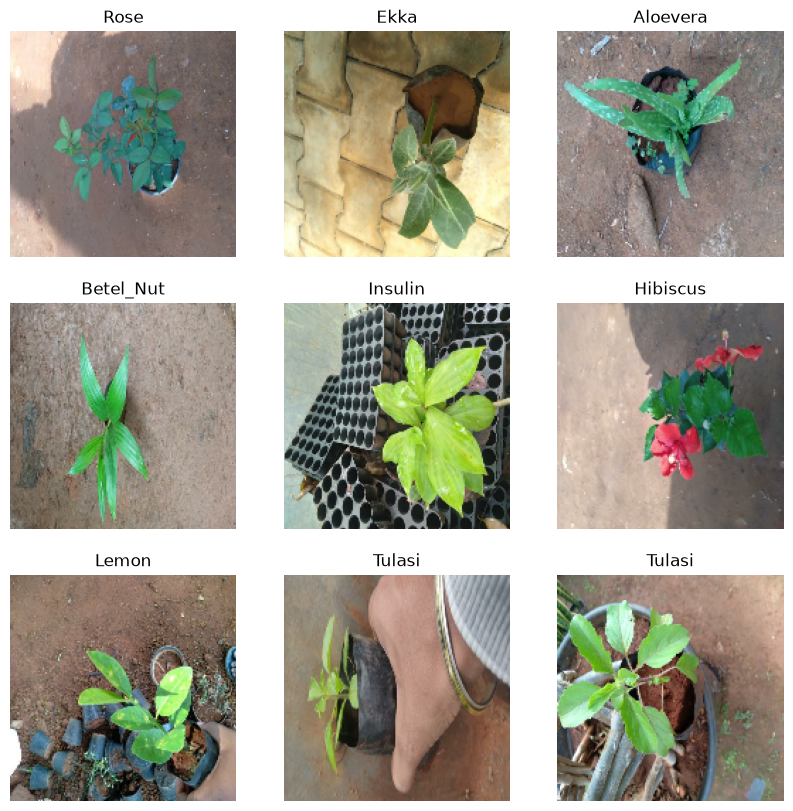

In [17]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[np.argmax(labels[i])])
        plt.axis("off")
plt.show()

In [21]:
data_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
])

base = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_aug(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
print("Model ready. Classes:", len(class_names))

Model ready. Classes: 40


In [22]:
EPOCHS_1 = 15   # test run first; change to 15 for the full training

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=4, restore_best_weights=True)

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=EPOCHS_1, callbacks=[early_stop])

Epoch 1/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 42s 153ms/step - accuracy: 0.4261 - loss: 2.1684 - val_accuracy: 0.6890 - val_loss: 1.1158
Epoch 2/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 41s 151ms/step - accuracy: 0.7124 - loss: 1.0009 - val_accuracy: 0.7763 - val_loss: 0.7631
Epoch 3/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 43s 168ms/step - accuracy: 0.7881 - loss: 0.7219 - val_accuracy: 0.8134 - val_loss: 0.6233
Epoch 4/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 78s 152ms/step - accuracy: 0.8162 - loss: 0.6193 - val_accuracy: 0.8158 - val_loss: 0.5907
Epoch 5/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 42s 156ms/step - accuracy: 0.8457 - loss: 0.5203 - val_accuracy: 0.8325 - val_loss: 0.5594
Epoch 6/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 39s 149ms/step - accuracy: 0.8583 - loss: 0.4708 - val_accuracy: 0.8624 - val_loss: 0.4808
Epoch 7/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 40s 146ms/step - accuracy: 0.8664 - loss: 0.4254 - val_accuracy: 0.8577 - val_loss: 0.4741
Epoch 8/15
254/254 ━━━━━━━━━━━━━━━━━━━━ 41s 148ms/step - accuracy: 0.8714 - loss: 0

In [23]:
EPOCHS_2 = 10   # test run first; change to 10 for the full training

base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

history_ft = model.fit(train_ds, validation_data=val_ds,
                       epochs=EPOCHS_2, callbacks=[early_stop])

Epoch 1/10
254/254 ━━━━━━━━━━━━━━━━━━━━ 69s 248ms/step - accuracy: 0.6604 - loss: 1.1506 - val_accuracy: 0.8493 - val_loss: 0.4695
Epoch 2/10
254/254 ━━━━━━━━━━━━━━━━━━━━ 46s 180ms/step - accuracy: 0.7590 - loss: 0.8351 - val_accuracy: 0.8541 - val_loss: 0.4629
Epoch 3/10
254/254 ━━━━━━━━━━━━━━━━━━━━ 80s 172ms/step - accuracy: 0.7962 - loss: 0.7029 - val_accuracy: 0.8636 - val_loss: 0.4521
Epoch 4/10
254/254 ━━━━━━━━━━━━━━━━━━━━ 82s 174ms/step - accuracy: 0.8174 - loss: 0.6295 - val_accuracy: 0.8660 - val_loss: 0.4319
Epoch 5/10
254/254 ━━━━━━━━━━━━━━━━━━━━ 45s 176ms/step - accuracy: 0.8374 - loss: 0.5837 - val_accuracy: 0.8744 - val_loss: 0.4188
Epoch 6/10
254/254 ━━━━━━━━━━━━━━━━━━━━ 80s 170ms/step - accuracy: 0.8457 - loss: 0.5193 - val_accuracy: 0.8804 - val_loss: 0.4010
Epoch 7/10
254/254 ━━━━━━━━━━━━━━━━━━━━ 83s 176ms/step - accuracy: 0.8583 - loss: 0.4726 - val_accuracy: 0.8840 - val_loss: 0.3830
Epoch 8/10
254/254 ━━━━━━━━━━━━━━━━━━━━ 45s 176ms/step - accuracy: 0.8704 - loss: 0

In [24]:
model.save(os.path.join(MODEL_DIR, "herbal_model.keras"))
with open(os.path.join(MODEL_DIR, "classes.json"), "w") as f:
    json.dump(class_names, f)
print("Saved.")

Saved.


In [7]:
with open(os.path.join(MODEL_DIR, "classes.json")) as f:
    class_names = json.load(f)

print(len(class_names), "classes")

missing = [c for c in class_names if c not in plant_info]
print(f"Info written for {len(plant_info)} plants. Still missing: {len(missing)}")
print(missing)

40 classes
Info written for 3 plants. Still missing: 37
['Amla', 'Amruta_Balli', 'Arali', 'Ashoka', 'Ashwagandha', 'Avacado', 'Bamboo', 'Basale', 'Betel', 'Betel_Nut', 'Brahmi', 'Castor', 'Curry_Leaf', 'Doddapatre', 'Ekka', 'Ganike', 'Gauva', 'Geranium', 'Henna', 'Hibiscus', 'Honge', 'Insulin', 'Jasmine', 'Lemon', 'Lemon_grass', 'Mango', 'Mint', 'Nagadali', 'Nithyapushpa', 'Nooni', 'Pappaya', 'Pepper', 'Pomegranate', 'Raktachandini', 'Rose', 'Sapota', 'Wood_sorel']


In [6]:
import os, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

BASE_DIR  = r"C:\Users\LENOVO\Desktop\AI project\Medicinal-plant"
MODEL_DIR = os.path.join(BASE_DIR, "models")
IMG_SIZE  = (160, 160)

# 1. Load the trained model and the plant names
model = tf.keras.models.load_model(os.path.join(MODEL_DIR, "herbal_model.keras"))
with open(os.path.join(MODEL_DIR, "classes.json")) as f:
    class_names = json.load(f)

# 2. Load the plant information (if the file exists)
info_path = os.path.join(BASE_DIR, "plant_info.json")
if os.path.exists(info_path):
    with open(info_path, encoding="utf-8") as f:
        plant_info = json.load(f)
else:
    plant_info = {}

# 3. Define the prediction function
def predict_plant(img_path, threshold=0.60, top_k=3):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    arr = np.expand_dims(tf.keras.utils.img_to_array(img), 0)
    probs = model.predict(arr, verbose=0)[0]
    top = np.argsort(probs)[::-1][:top_k]

    plt.imshow(img); plt.axis("off"); plt.show()

    print("Top predictions:")
    for i in top:
        print(f"  {class_names[i]:20s} {probs[i]:.0%}")

    best = int(top[0])
    if probs[best] < threshold:
        print("\nPlant not recognized with enough confidence. Try a clearer photo.")
        return

    name = class_names[best]
    print(f"\nDetected: {name}")
    info = plant_info.get(name)
    if info:
        print("Scientific name:", info["scientific_name"])
        print("Uses:")
        for u in info["uses"]:
            print(" -", u)
        print("How to use:", info["how_to_use"])
        print("Precautions:", info["precautions"])
    else:
        print("Information for this plant has not been added yet.")
    print("\nFor educational purposes only. Not medical advice.")

print("Ready.", len(class_names), "plants,", len(plant_info), "with information.")

Ready. 40 plants, 3 with information.


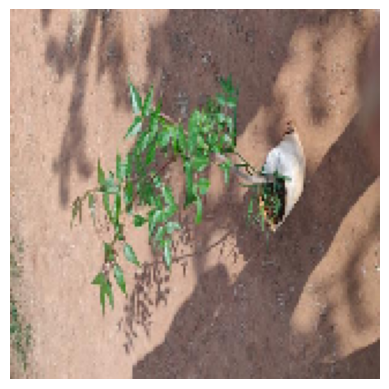

Top predictions:
  Neem                 90%
  Mango                5%
  Pomegranate          2%

Detected: Neem
Scientific name: Azadirachta indica
Uses:
 - Traditionally used for skin problems
 - Used in oral and dental care
How to use: Leaves are used in pastes or washes; twigs are traditionally used for cleaning teeth.
Precautions: Not recommended during pregnancy or for young children. Consult a doctor.

For educational purposes only. Not medical advice.


In [7]:
predict_plant(r"C:\Users\LENOVO\Desktop\AI project\test_photo.jpg")

In [8]:
import os, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import pandas as pd

BASE_DIR      = r"C:\Users\LENOVO\Desktop\AI project\Medicinal-plant"
MODEL_DIR     = os.path.join(BASE_DIR, "models")
template_path = os.path.join(BASE_DIR, "plant_info_template.csv")
info_path     = os.path.join(BASE_DIR, "plant_info.json")

with open(os.path.join(MODEL_DIR, "classes.json")) as f:
    class_names = json.load(f)

if os.path.exists(info_path):
    with open(info_path, encoding="utf-8") as f:
        plant_info = json.load(f)
else:
    plant_info = {}

needed = ["class_name", "scientific_name", "uses", "how_to_use", "precautions"]

def apply_batch(batch):
    global plant_info
    # read the CSV, or rebuild it from plant_info if missing or damaged
    df = pd.DataFrame()
    if os.path.exists(template_path):
        try:
            df = pd.read_csv(template_path, encoding="utf-8-sig", sep=None, engine="python").fillna("")
            df.columns = [str(c).strip().lower().replace(" ", "_") for c in df.columns]
        except Exception as e:
            print("Could not read the CSV:", e)
    if not all(c in df.columns for c in needed):
        print("Building a fresh CSV from saved information.")
        df = pd.DataFrame([{
            "class_name": c,
            "scientific_name": plant_info.get(c, {}).get("scientific_name", ""),
            "uses": "; ".join(plant_info.get(c, {}).get("uses", [])),
            "how_to_use": plant_info.get(c, {}).get("how_to_use", ""),
            "precautions": plant_info.get(c, {}).get("precautions", ""),
        } for c in class_names])

    # write the batch
    for name, d in batch.items():
        idx = df.index[df["class_name"] == name]
        if len(idx) == 0:
            print("Name not found in CSV:", name)
            continue
        for col, val in d.items():
            df.loc[idx, col] = val
    df.to_csv(template_path, index=False, encoding="utf-8-sig")

    # rebuild plant_info and save the JSON
    plant_info = {}
    for _, r in df.iterrows():
        plant_info[r["class_name"]] = {
            "scientific_name": r["scientific_name"],
            "uses": [u.strip() for u in str(r["uses"]).split(";") if u.strip()],
            "how_to_use": r["how_to_use"],
            "precautions": r["precautions"],
        }
    with open(info_path, "w", encoding="utf-8") as f:
        json.dump(plant_info, f, indent=2, ensure_ascii=False)

    left = [k for k, v in plant_info.items() if not v["uses"]]
    print("Plants still without uses:", len(left))

done = [k for k, v in plant_info.items() if v.get("uses")]
print(len(class_names), "plants,", len(done), "with information")

40 plants, 40 with information


In [9]:
batch1 = {
 "Amla": {
  "scientific_name": "Phyllanthus emblica",
  "uses": "Rich natural source of vitamin C; Traditionally used to support digestion and immunity; Traditionally used in hair and skin care",
  "how_to_use": "Fresh fruit, juice, or dried powder; also an ingredient in Ayurvedic preparations such as Chyawanprash.",
  "precautions": "May lower blood sugar, so people on diabetes medicines should consult a doctor. Excess may cause acidity."
 },
 "Amruta_Balli": {
  "scientific_name": "Tinospora cordifolia (Giloy)",
  "uses": "Traditionally used for fever and general weakness; Traditionally used to support immunity; Used in Ayurvedic digestive and tonic formulations",
  "how_to_use": "Stem decoction or powder, taken as advised by an Ayurvedic practitioner.",
  "precautions": "May lower blood sugar and affect immune-related conditions or medicines. Rare liver problems have been reported with some products. Avoid in pregnancy. Consult a doctor."
 },
 "Arali": {
  "scientific_name": "Ficus religiosa (Peepal) - verify species",
  "uses": "Leaves and bark traditionally used for skin problems and wounds; Traditionally used for digestive complaints",
  "how_to_use": "Bark or leaf preparations are traditionally used only under practitioner guidance.",
  "precautions": "Limited safety information. Avoid in pregnancy and do not self-medicate. Consult a doctor."
 },
 "Ashoka": {
  "scientific_name": "Saraca asoca - verify species",
  "uses": "Bark traditionally used in Ayurveda for women's reproductive health concerns, such as menstrual complaints",
  "how_to_use": "Bark preparations are used only as advised by an Ayurvedic practitioner.",
  "precautions": "Avoid in pregnancy. Do not self-medicate. Consult a doctor."
 },
 "Ashwagandha": {
  "scientific_name": "Withania somnifera",
  "uses": "Traditionally used to help the body cope with stress; Traditionally used for tiredness and general strength; Traditionally used to support sleep",
  "how_to_use": "Root powder, usually mixed with milk or water, as advised by a practitioner.",
  "precautions": "Avoid in pregnancy. Consult a doctor if you have thyroid problems, an autoimmune condition, or take sedatives or diabetes medicines. Rare liver problems have been reported."
 },
 "Avacado": {
  "scientific_name": "Persea americana",
  "uses": "Fruit is nutritious, with healthy fats, fibre, and potassium; Fruit and oil are used in skin and hair care",
  "how_to_use": "Eat the ripe fruit; oil or pulp is used on skin and hair.",
  "precautions": "People with latex allergy may react to the fruit. Leaves, skin, and seed are toxic to many pets and birds. Do not use leaves or seed for self-medication."
 },
 "Bamboo": {
  "scientific_name": "Bambusa vulgaris - verify species",
  "uses": "Leaves traditionally used in folk medicine for cough and fever; Young shoots are eaten as food after cooking",
  "how_to_use": "Leaf decoction in folk use; shoots must be boiled before eating.",
  "precautions": "Raw bamboo shoots contain natural toxins and must be cooked. Do not self-medicate. Consult a doctor."
 },
 "Basale": {
  "scientific_name": "Basella alba (Malabar spinach)",
  "uses": "Leafy vegetable rich in iron and vitamins; Traditionally used as a mild laxative and cooling food; Leaf paste traditionally applied on minor skin problems",
  "how_to_use": "Leaves are cooked as a vegetable or in soups.",
  "precautions": "Contains oxalates, so people prone to kidney stones should eat it in moderation. Cook before eating."
 },
}

# write into the CSV
df = pd.read_csv(template_path, encoding="utf-8-sig").fillna("")
for name, d in batch1.items():
    idx = df.index[df["class_name"] == name]
    if len(idx) == 0:
        print("Name not found in CSV:", name)
        continue
    for col, val in d.items():
        df.loc[idx, col] = val
df.to_csv(template_path, index=False, encoding="utf-8-sig")

# rebuild plant_info and save the JSON
plant_info = {}
for _, r in df.iterrows():
    plant_info[r["class_name"]] = {
        "scientific_name": r["scientific_name"],
        "uses": [u.strip() for u in r["uses"].split(";") if u.strip()],
        "how_to_use": r["how_to_use"],
        "precautions": r["precautions"],
    }
with open(os.path.join(BASE_DIR, "plant_info.json"), "w", encoding="utf-8") as f:
    json.dump(plant_info, f, indent=2, ensure_ascii=False)

incomplete = [k for k, v in plant_info.items() if not v["uses"]]
print("Plants still without uses:", len(incomplete))

ParserError: Error tokenizing data. C error: Expected 1 fields in line 3, saw 4


In [10]:
import shutil

needed = ["class_name", "scientific_name", "uses", "how_to_use", "precautions"]

def fresh_rows():
    rows = []
    for c in class_names:
        info = plant_info.get(c, {})
        rows.append({
            "class_name": c,
            "scientific_name": info.get("scientific_name", ""),
            "uses": "; ".join(info.get("uses", [])),
            "how_to_use": info.get("how_to_use", ""),
            "precautions": info.get("precautions", ""),
        })
    return rows

# 1. read the CSV in a flexible way
try:
    df = pd.read_csv(template_path, encoding="utf-8-sig", sep=None, engine="python").fillna("")
    df.columns = [str(c).strip().lower().replace(" ", "_") for c in df.columns]
except Exception as e:
    print("Could not read the CSV:", e)
    df = pd.DataFrame()

print("Columns found:", list(df.columns))

# 2. if the layout is wrong, back it up and rebuild a clean one
if not all(c in df.columns for c in needed):
    print("CSV layout was wrong. Backing it up and rebuilding it.")
    if os.path.exists(template_path):
        shutil.copy(template_path, template_path + ".bak")
    df = pd.DataFrame(fresh_rows())

# 3. write batch 1 into the table
for name, d in batch1.items():
    idx = df.index[df["class_name"] == name]
    if len(idx) == 0:
        print("Name not found in CSV:", name)
        continue
    for col, val in d.items():
        df.loc[idx, col] = val

df.to_csv(template_path, index=False, encoding="utf-8-sig")

# 4. rebuild plant_info and save the JSON
plant_info = {}
for _, r in df.iterrows():
    plant_info[r["class_name"]] = {
        "scientific_name": r["scientific_name"],
        "uses": [u.strip() for u in str(r["uses"]).split(";") if u.strip()],
        "how_to_use": r["how_to_use"],
        "precautions": r["precautions"],
    }
with open(os.path.join(BASE_DIR, "plant_info.json"), "w", encoding="utf-8") as f:
    json.dump(plant_info, f, indent=2, ensure_ascii=False)

incomplete = [k for k, v in plant_info.items() if not v["uses"]]
print("Plants still without uses:", len(incomplete))

Columns found: ['class_name', 'scientific_name', 'uses', 'how_to_use', 'precautions']
Plants still without uses: 0


In [11]:
batch2 = {
 "Betel": {
  "scientific_name": "Piper betle",
  "uses": "Leaves traditionally used as a mouth freshener and to support digestion; Traditionally used for cough and minor wounds in folk medicine; Used in religious and cultural practices",
  "how_to_use": "Fresh leaf is chewed in small amounts or used in traditional preparations. Leaf paste is applied to minor skin problems.",
  "precautions": "Do not chew with tobacco or areca nut, which raises the risk of oral cancer. Excess use may irritate the mouth. Consult a doctor."
 },
 "Betel_Nut": {
  "scientific_name": "Areca catechu",
  "uses": "Seed is used in traditional and cultural practices; Traditionally used in some Ayurvedic preparations",
  "how_to_use": "Not recommended for home use. Use only in preparations advised by a qualified practitioner.",
  "precautions": "Regular chewing is linked to oral cancer and mouth diseases, and the International Agency for Research on Cancer classifies it as carcinogenic to humans. Habit-forming. Avoid in pregnancy. Not for self-medication."
 },
 "Brahmi": {
  "scientific_name": "Bacopa monnieri",
  "uses": "Traditionally used to support memory and learning; Traditionally used to help with stress and anxiety; Used in Ayurvedic nerve tonics",
  "how_to_use": "Leaf juice, powder, or extract, taken as advised by an Ayurvedic practitioner.",
  "precautions": "May cause stomach upset or nausea. Consult a doctor if you take thyroid, sedative, or other regular medicines, and avoid in pregnancy."
 },
 "Castor": {
  "scientific_name": "Ricinus communis",
  "uses": "Seed oil (castor oil) is traditionally used as a laxative and in hair and skin care; Oil is applied externally in massage for joint and muscle comfort",
  "how_to_use": "Only the refined oil is used, and only in amounts advised by a doctor. Never eat the seeds or leaves.",
  "precautions": "The seeds are highly toxic because they contain ricin. Oil should not be used in pregnancy, as it may induce labour. Do not self-medicate."
 },
 "Curry_Leaf": {
  "scientific_name": "Murraya koenigii",
  "uses": "Common cooking herb that adds flavour and nutrients such as iron; Traditionally used to support digestion; Traditionally used in hair and skin care",
  "how_to_use": "Fresh leaves are added to food. Leaf paste or oil is used in hair care.",
  "precautions": "Safe as food in normal amounts. Medicinal use in larger amounts should be discussed with a doctor, especially if you take diabetes medicines."
 },
 "Doddapatre": {
  "scientific_name": "Coleus amboinicus (Plectranthus amboinicus) - verify species",
  "uses": "Leaves traditionally used for cough, cold, and throat irritation; Traditionally used for indigestion; Leaf juice traditionally applied to insect bites and minor skin problems",
  "how_to_use": "A few leaves are used in tea, decoction, or juice, usually with honey. The leaf is also eaten in small amounts in local dishes.",
  "precautions": "Avoid large amounts in pregnancy. Consult a doctor if symptoms last more than a few days."
 },
 "Ekka": {
  "scientific_name": "Calotropis gigantea - verify species",
  "uses": "Traditionally used in folk and Ayurvedic medicine for skin conditions and joint pain, in carefully prepared forms; Has cultural and religious importance",
  "how_to_use": "Not for home use. Use only under the guidance of a qualified practitioner.",
  "precautions": "The milky latex is toxic and can cause severe skin and eye irritation. Taking any part by mouth can be dangerous. Avoid contact with eyes. Not for self-medication."
 },
 "Ganike": {
  "scientific_name": "Not confirmed - verify species (local name)",
  "uses": "Used in traditional and folk medicine, but details are not confirmed",
  "how_to_use": "Information not confirmed. Do not use without confirming the species and advice from a practitioner.",
  "precautions": "Species not confirmed, so safety is unknown. Do not self-medicate. Consult a doctor."
 },
}

needed = ["class_name", "scientific_name", "uses", "how_to_use", "precautions"]

# read the CSV, fall back to a clean one if the layout is wrong
try:
    df = pd.read_csv(template_path, encoding="utf-8-sig", sep=None, engine="python").fillna("")
    df.columns = [str(c).strip().lower().replace(" ", "_") for c in df.columns]
except Exception as e:
    print("Could not read the CSV:", e)
    df = pd.DataFrame()

if not all(c in df.columns for c in needed):
    print("CSV layout was wrong. Rebuilding it from plant_info.")
    df = pd.DataFrame([{
        "class_name": c,
        "scientific_name": plant_info.get(c, {}).get("scientific_name", ""),
        "uses": "; ".join(plant_info.get(c, {}).get("uses", [])),
        "how_to_use": plant_info.get(c, {}).get("how_to_use", ""),
        "precautions": plant_info.get(c, {}).get("precautions", ""),
    } for c in class_names])

# write batch 2
for name, d in batch2.items():
    idx = df.index[df["class_name"] == name]
    if len(idx) == 0:
        print("Name not found in CSV:", name)
        continue
    for col, val in d.items():
        df.loc[idx, col] = val

df.to_csv(template_path, index=False, encoding="utf-8-sig")

# rebuild plant_info and save JSON
plant_info = {}
for _, r in df.iterrows():
    plant_info[r["class_name"]] = {
        "scientific_name": r["scientific_name"],
        "uses": [u.strip() for u in str(r["uses"]).split(";") if u.strip()],
        "how_to_use": r["how_to_use"],
        "precautions": r["precautions"],
    }
with open(os.path.join(BASE_DIR, "plant_info.json"), "w", encoding="utf-8") as f:
    json.dump(plant_info, f, indent=2, ensure_ascii=False)

incomplete = [k for k, v in plant_info.items() if not v["uses"]]
print("Plants still without uses:", len(incomplete))

Plants still without uses: 0


In [12]:
batch3 = {
 "Gauva": {
  "scientific_name": "Psidium guajava",
  "uses": "Fruit is rich in vitamin C and fibre; Leaves traditionally used for diarrhoea and as a mouth rinse for gum and tooth problems; Leaf paste traditionally applied on minor wounds",
  "how_to_use": "Eat the ripe fruit. Leaf decoction is used as a gargle or taken in small amounts as advised by a practitioner.",
  "precautions": "Leaf extracts may lower blood sugar, so people on diabetes medicines should consult a doctor. Avoid medicinal doses in pregnancy."
 },
 "Geranium": {
  "scientific_name": "Pelargonium graveolens (rose geranium) - verify species",
  "uses": "Leaves and essential oil are used for fragrance and aromatherapy; Oil is used in skin care products; Traditionally used in folk medicine for minor skin problems",
  "how_to_use": "Diluted essential oil is used on skin or in diffusers. Leaves are used in teas and scented preparations.",
  "precautions": "Essential oil should not be swallowed and can irritate skin, so dilute it and do a patch test. Avoid in pregnancy. Keep away from children and pets."
 },
 "Henna": {
  "scientific_name": "Lawsonia inermis",
  "uses": "Leaf paste is used as a natural dye for hair and skin; Traditionally used for scalp and hair care; Traditionally used as a cooling application on skin",
  "how_to_use": "Dried leaf powder is mixed with water into a paste and applied to hair or skin.",
  "precautions": "Do a patch test first. Avoid 'black henna' products, which can contain harmful chemicals. Henna is not advised for infants or people with G6PD deficiency. Not for eating."
 },
 "Hibiscus": {
  "scientific_name": "Hibiscus rosa-sinensis",
  "uses": "Flowers and leaves traditionally used in hair care; Flowers traditionally used in cooling drinks and folk medicine; Widely used as an ornamental and in worship",
  "how_to_use": "Flower or leaf paste is applied to hair. Flower infusion is taken in small amounts in traditional use.",
  "precautions": "May lower blood pressure and blood sugar. Avoid medicinal amounts in pregnancy. Consult a doctor before regular internal use."
 },
 "Honge": {
  "scientific_name": "Pongamia pinnata",
  "uses": "Seed oil (karanja oil) traditionally applied for skin conditions; Leaves and bark used in folk medicine for skin and wound care",
  "how_to_use": "Oil is used externally only, under the guidance of a practitioner.",
  "precautions": "Seeds and oil are bitter and toxic if swallowed. Do a patch test before skin use. Not for self-medication."
 },
 "Insulin": {
  "scientific_name": "Costus igneus",
  "uses": "Leaves traditionally used in folk medicine to support blood sugar management; Leaves are sometimes chewed or added to food in small amounts",
  "how_to_use": "Fresh leaves are chewed or taken as juice in traditional use.",
  "precautions": "Scientific evidence is limited. It is NOT a substitute for diabetes medicines or insulin. Do not change or stop treatment without a doctor, because blood sugar may fall too low or too high."
 },
 "Jasmine": {
  "scientific_name": "Jasminum sambac or Jasminum officinale - verify species",
  "uses": "Flowers are used for fragrance, tea, and aromatherapy; Traditionally used for relaxation and headache relief; Flowers and oil traditionally used in skin and hair care",
  "how_to_use": "Flowers are used in tea or hair oils. Diluted oil is used in aromatherapy.",
  "precautions": "May cause allergy or skin irritation in some people, so patch test first. Essential oil should not be swallowed. Avoid medicinal use in pregnancy."
 },
 "Lemon": {
  "scientific_name": "Citrus limon",
  "uses": "Rich source of vitamin C; Traditionally used with warm water and honey for cough and sore throat; Used to support digestion and as a flavouring",
  "how_to_use": "Juice is diluted in water or added to food and tea.",
  "precautions": "Acidic juice can damage tooth enamel and worsen acid reflux in some people. Lemon juice on skin followed by sun exposure can cause burns or dark patches."
 },
}

needed = ["class_name", "scientific_name", "uses", "how_to_use", "precautions"]

# read the CSV, fall back to a clean one if the layout is wrong
try:
    df = pd.read_csv(template_path, encoding="utf-8-sig", sep=None, engine="python").fillna("")
    df.columns = [str(c).strip().lower().replace(" ", "_") for c in df.columns]
except Exception as e:
    print("Could not read the CSV:", e)
    df = pd.DataFrame()

if not all(c in df.columns for c in needed):
    print("CSV layout was wrong. Rebuilding it from plant_info.")
    df = pd.DataFrame([{
        "class_name": c,
        "scientific_name": plant_info.get(c, {}).get("scientific_name", ""),
        "uses": "; ".join(plant_info.get(c, {}).get("uses", [])),
        "how_to_use": plant_info.get(c, {}).get("how_to_use", ""),
        "precautions": plant_info.get(c, {}).get("precautions", ""),
    } for c in class_names])

# write batch 3
for name, d in batch3.items():
    idx = df.index[df["class_name"] == name]
    if len(idx) == 0:
        print("Name not found in CSV:", name)
        continue
    for col, val in d.items():
        df.loc[idx, col] = val

df.to_csv(template_path, index=False, encoding="utf-8-sig")

# rebuild plant_info and save JSON
plant_info = {}
for _, r in df.iterrows():
    plant_info[r["class_name"]] = {
        "scientific_name": r["scientific_name"],
        "uses": [u.strip() for u in str(r["uses"]).split(";") if u.strip()],
        "how_to_use": r["how_to_use"],
        "precautions": r["precautions"],
    }
with open(os.path.join(BASE_DIR, "plant_info.json"), "w", encoding="utf-8") as f:
    json.dump(plant_info, f, indent=2, ensure_ascii=False)

incomplete = [k for k, v in plant_info.items() if not v["uses"]]
print("Plants still without uses:", len(incomplete))
print(incomplete)

Plants still without uses: 0
[]


In [7]:
import os, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import pandas as pd

BASE_DIR      = r"C:\Users\LENOVO\Desktop\AI project\Medicinal-plant"
MODEL_DIR     = os.path.join(BASE_DIR, "models")
template_path = os.path.join(BASE_DIR, "plant_info_template.csv")

with open(os.path.join(MODEL_DIR, "classes.json")) as f:
    class_names = json.load(f)

info_path = os.path.join(BASE_DIR, "plant_info.json")
if os.path.exists(info_path):
    with open(info_path, encoding="utf-8") as f:
        plant_info = json.load(f)
else:
    plant_info = {}

done = [k for k, v in plant_info.items() if v.get("uses")]
print(len(class_names), "plants,", len(done), "with information")

40 plants, 40 with information


In [13]:
batch4 = {
 "Lemon_grass": {
  "scientific_name": "Cymbopogon citratus",
  "uses": "Used as a herbal tea and flavouring; Traditionally used to support digestion and relieve stomach discomfort; Traditionally used for cold, fever, and mild aches; Oil is used in aromatherapy and as a mosquito repellent",
  "how_to_use": "Fresh or dried leaves are steeped in hot water as tea or added to food. Diluted oil is used externally.",
  "precautions": "Essential oil should not be swallowed and can irritate skin, so dilute it. Avoid medicinal amounts in pregnancy. Consult a doctor if you take regular medicines."
 },
 "Mango": {
  "scientific_name": "Mangifera indica",
  "uses": "Fruit is rich in vitamins A and C and fibre; Leaves traditionally used in folk medicine for blood sugar support and throat irritation; Bark and seed are used in traditional preparations",
  "how_to_use": "Eat the ripe fruit. Leaf decoction is used in folk practice in small amounts.",
  "precautions": "Mango sap and peel contain urushiol-like compounds that can cause skin rashes in sensitive people. Leaf use may lower blood sugar, so consult a doctor if you take diabetes medicines. Ripe fruit is high in natural sugar."
 },
 "Mint": {
  "scientific_name": "Mentha species (commonly Mentha spicata or Mentha piperita) - verify species",
  "uses": "Traditionally used to support digestion and relieve gas and bloating; Used in tea for nausea and headache relief; Used as a flavouring and for fresh breath",
  "how_to_use": "Fresh or dried leaves are used in tea, chutneys, and food.",
  "precautions": "May worsen acid reflux in some people. Peppermint oil should not be used on or near the face of young children, and should be diluted before skin use. Consult a doctor before medicinal use in pregnancy."
 },
 "Nagadali": {
  "scientific_name": "Not confirmed - verify species (local name)",
  "uses": "Used in traditional and folk medicine, but details are not confirmed",
  "how_to_use": "Information not confirmed. Do not use without confirming the species and advice from a practitioner.",
  "precautions": "Species not confirmed, so safety is unknown. Do not self-medicate. Consult a doctor."
 },
 "Nithyapushpa": {
  "scientific_name": "Catharanthus roseus",
  "uses": "Source of alkaloids used by the pharmaceutical industry for certain cancer medicines; Traditionally used in folk medicine for diabetes, but safe use is not established; Widely grown as an ornamental plant",
  "how_to_use": "Not for home use. Do not eat or drink preparations of this plant.",
  "precautions": "Toxic if taken by mouth. It can harm the blood, nerves, and liver. Not for self-medication and keep away from children and pets."
 },
 "Nooni": {
  "scientific_name": "Morinda citrifolia (Noni)",
  "uses": "Fruit juice is traditionally used as a health tonic; Traditionally used in folk medicine for joint pain, digestion, and general wellbeing",
  "how_to_use": "Ripe fruit juice is taken in small amounts in traditional use, or leaves are used externally.",
  "precautions": "Has been linked to liver problems in some people. Contains high potassium, so people with kidney disease should avoid it. Avoid in pregnancy. Consult a doctor first."
 },
 "Pappaya": {
  "scientific_name": "Carica papaya",
  "uses": "Ripe fruit is rich in vitamin C and fibre and supports digestion; Leaves traditionally used in folk medicine, for example for low platelet counts, though evidence is limited; Raw fruit and latex are used in traditional remedies and meat tenderising",
  "how_to_use": "Eat the ripe fruit. Leaf juice is used in folk practice only on medical advice.",
  "precautions": "Unripe papaya and latex should be avoided in pregnancy, because they may cause contractions. Latex can cause allergy and skin irritation. Fever with low platelets needs a doctor, not home treatment."
 },
}

apply_batch(batch4)

Plants still without uses: 0


In [14]:
batch5 = {
 "Pepper": {
  "scientific_name": "Piper nigrum (black pepper) - verify species",
  "uses": "Common spice used for flavour; Traditionally used for cough, cold, and sore throat; Traditionally used to support digestion and appetite",
  "how_to_use": "Ground or whole pepper is added to food, tea, or warm milk. A pinch is used with honey in traditional home remedies.",
  "precautions": "Large amounts can irritate the stomach and worsen acid reflux or ulcers. Pepper can increase absorption of some medicines, so consult a doctor if you take regular medicines. Avoid medicinal amounts in pregnancy."
 },
 "Pomegranate": {
  "scientific_name": "Punica granatum",
  "uses": "Fruit and juice are rich in antioxidants and vitamin C; Rind and bark traditionally used for diarrhoea and mouth or throat problems; Flowers and rind used in folk medicine",
  "how_to_use": "Eat the fruit or drink the juice. Dried rind powder is used in traditional preparations on practitioner advice.",
  "precautions": "Can interact with some medicines, including blood pressure and blood-thinning medicines. Root and stem bark can be toxic, so use only the fruit unless a practitioner advises otherwise. Consult a doctor before medicinal use."
 },
 "Raktachandini": {
  "scientific_name": "Pterocarpus santalinus (red sandalwood) - verify species",
  "uses": "Heartwood paste is traditionally used for skin care and cooling applications; Traditionally used in Ayurveda for skin conditions and inflammation; Used as a natural red dye",
  "how_to_use": "Wood powder is made into a paste with water or rose water and applied to the skin.",
  "precautions": "This is an endangered, legally protected tree, so do not collect or trade it without permission. Do a patch test before skin use. Not for self-medication by mouth."
 },
 "Rose": {
  "scientific_name": "Rosa species (commonly Rosa x damascena) - verify species",
  "uses": "Petals and rose water are used in skin care and as a cooling application; Petals traditionally used in tea and in Ayurvedic preparations such as gulkand to support digestion; Used for fragrance and aromatherapy",
  "how_to_use": "Rose water is applied on skin or eyes only if it is meant for that purpose. Petals are used in tea or sweet preparations.",
  "precautions": "Some people are allergic to rose products, so do a patch test. Essential oil should not be swallowed. Use only unsprayed petals for eating."
 },
 "Sapota": {
  "scientific_name": "Manilkara zapota",
  "uses": "Fruit is a good source of energy, fibre, and vitamin C; Bark and unripe fruit traditionally used in folk medicine for diarrhoea; Latex is used in traditional preparations",
  "how_to_use": "Eat the ripe fruit. Other parts are used only in folk practice.",
  "precautions": "Unripe fruit is astringent and can cause mouth irritation. Seeds should not be eaten. The fruit is high in natural sugar, so people with diabetes should eat it in moderation."
 },
 "Wood_sorel": {
  "scientific_name": "Oxalis corniculata",
  "uses": "Leaves traditionally used in folk medicine for digestive complaints and fever; Leaf juice traditionally applied on minor skin problems; Leaves are sometimes eaten in small amounts for their sour taste",
  "how_to_use": "Leaves are used in small amounts in chutneys or in folk preparations.",
  "precautions": "Contains oxalates. People with kidney stones, gout, or kidney disease should avoid it, and large amounts can be harmful. Not for self-medication."
 },
}

apply_batch(batch5)

Plants still without uses: 0


In [15]:
missing = [c for c in class_names if not plant_info.get(c, {}).get("uses")]
print("Missing:", missing)

import pprint
pprint.pprint(plant_info["Tulasi"])

Missing: []
{'how_to_use': 'A few leaves boiled in water or made into tea; honey can be '
               'added.',
 'precautions': 'Avoid excess use during pregnancy. Consult a doctor.',
 'scientific_name': 'Ocimum tenuiflorum',
 'uses': ['Traditionally used for cough and cold',
          'Traditionally used to help with fever',
          'Supports general immunity']}


In [3]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sys
print(sys.executable)

C:\Users\LENOVO\python.exe


In [6]:
batch_final = {
 "Arali": {
  "scientific_name": "Nerium oleander (oleander)",
  "uses": "Highly poisonous plant that is not for home use, Traditionally used in very small amounts in specific processed Ayurvedic and Siddha preparations for skin conditions only under strict practitioner supervision, Widely grown as an ornamental plant",
  "how_to_use": "Never use this plant at home. It should only be taken as a processed, commercially prepared medicine prescribed by a registered practitioner.",
  "precautions": "Extremely toxic. All parts of the plant, including leaves, flowers, stems and sap, contain cardiac glycosides that can cause severe poisoning, irregular heartbeat and death, even from a small amount. Keep away from children and pets. If any part is swallowed, get emergency medical help immediately."
 },
 "Ashoka": {
  "scientific_name": "Saraca asoca",
  "uses": "Bark is traditionally used in Ayurveda for women's reproductive health concerns such as heavy or painful periods, Used in traditional tonic preparations for the uterus",
  "how_to_use": "Traditionally taken as a bark decoction, as the Ayurvedic preparation Ashokarishta, or as bark powder with milk or water, only as advised by a practitioner.",
  "precautions": "Avoid during pregnancy, as it may affect the uterus. Do not self-medicate for menstrual problems, because heavy or irregular bleeding needs a doctor to find the cause. Consult a practitioner before long-term use."
 },
 "Bamboo": {
  "scientific_name": "Bambusa vulgaris / Bambusa arundinacea",
  "uses": "Cooked young shoots are eaten as food and are a source of fibre, Bamboo manna (vanshlochan), the silica-rich deposit from the stem, is traditionally used in Ayurveda for cough and respiratory complaints, Leaves are used in folk medicine",
  "how_to_use": "Young shoots must be thoroughly boiled before eating. Vanshlochan is traditionally taken with honey in small amounts as advised by a practitioner.",
  "precautions": "Raw bamboo shoots contain cyanogenic compounds that are toxic, so never eat them raw. Avoid medicinal amounts in pregnancy. Do not self-medicate."
 },
 "Doddapatre": {
  "scientific_name": "Coleus amboinicus (Plectranthus amboinicus), also called Indian borage",
  "uses": "Leaves are traditionally used in home remedies for colds, cough and sore throat, Traditionally used for indigestion and gas, Leaves are used as a flavouring and in traditional snacks",
  "how_to_use": "Fresh leaf juice is slightly warmed and mixed with honey in traditional cough remedies. Fresh leaves can also be eaten in small amounts or dipped in batter to make bajji.",
  "precautions": "Generally considered safe in food amounts. Large amounts may irritate the stomach or cause a burning feeling in people with acidity. Do not give medicinal doses to infants or young children without asking a doctor, and never give honey to babies under one year. Avoid medicinal amounts in pregnancy."
 },
 "Ekka": {
  "scientific_name": "Calotropis gigantea / Calotropis procera",
  "uses": "Traditionally used externally in folk medicine for joint pain and skin problems, Root bark is used in some traditional preparations only under practitioner guidance, Has cultural and religious importance",
  "how_to_use": "Traditionally, mature leaves are smeared with oil, warmed and tied over a painful joint. Keep the milky latex away from eyes and broken skin. Do not take any part by mouth.",
  "precautions": "The milky latex is toxic and caustic. It can cause severe skin irritation and serious eye injury, including possible loss of vision. Taking it by mouth can be dangerous. Wash hands thoroughly after handling. Not for self-medication."
 },
 "Ganike": {
  "scientific_name": "Solanum nigrum (black nightshade)",
  "uses": "Cooked leaves and ripe berries are eaten as food in parts of South India, cooked with ingredients such as tamarind, onion and cumin, Traditionally used in Indian folk medicine for stomach complaints, dysentery and fever, Leaf preparations traditionally used for mouth ulcers, Juice traditionally applied to skin ulcers and skin problems, Traditionally used in some regions for liver complaints",
  "how_to_use": "Only thoroughly cooked leaves and fully ripe berries of a known edible type are eaten as food. Medicinal use is traditional only and should be under a practitioner's guidance.",
  "precautions": "Raw leaves and unripe or green berries can be toxic because of solanine-type compounds, and toxicity varies between types and regions. It can be confused with the more poisonous deadly nightshade (Atropa belladonna), so never eat it unless the plant is correctly identified. Not for self-medication. Avoid in pregnancy. Laboratory anticancer findings are from cells and animals only and do not mean it treats cancer."
 },
 "Geranium": {
  "scientific_name": "Pelargonium graveolens (rose geranium)",
  "uses": "Essential oil is used in aromatherapy to promote relaxation, Used in skin care products, for example to balance oily skin, Traditionally used in folk medicine for minor skin problems",
  "how_to_use": "Dilute the essential oil in a carrier oil such as coconut or jojoba oil before applying to skin, or use it in a room diffuser.",
  "precautions": "Never swallow the essential oil. Do a patch test first, because it can cause skin irritation or allergic reactions. Avoid in pregnancy. Keep away from children and pets."
 },
 "Jasmine": {
  "scientific_name": "Jasminum officinale / Jasminum sambac",
  "uses": "Flowers are used in tea, aromatherapy and perfumery for relaxation, Traditionally used to ease menstrual discomfort, Used in skin and hair care",
  "how_to_use": "Steep dried petals in hot water for a calming tea. Diluted essential oil can be used in a diffuser or for massage.",
  "precautions": "Jasmine tea in normal amounts is generally considered safe. Avoid large or medicinal amounts in pregnancy. Essential oil should not be swallowed. Do a patch test, as it can cause skin allergy."
 },
 "Mint": {
  "scientific_name": "Mentha piperita (peppermint) / Mentha spicata (spearmint)",
  "uses": "Traditionally used to ease indigestion, gas and bloating, Peppermint is used for irritable bowel symptoms and to relieve nasal congestion, Used for fresh breath and as a flavouring",
  "how_to_use": "Steep fresh leaves in hot water for tea, or add fresh leaves to salads, chutneys and food.",
  "precautions": "May worsen acid reflux or heartburn. Do not apply peppermint oil on or near the face of infants and young children, because it can cause breathing problems. Dilute essential oil before skin use. Consult a doctor before medicinal use in pregnancy."
 },
 "Nagadali": {
  "scientific_name": "Ruta graveolens (common rue)",
  "uses": "Has a long history in traditional European and folk medicine, but internal use has largely been dropped because of toxicity, Applied on the skin in some traditions though this is risky, Used sparingly as a bitter culinary herb in the past, Grown as an ornamental and insect-repelling plant",
  "how_to_use": "Not recommended for home use. Internal use is discouraged because the plant is toxic. Any use should be only under the guidance of a qualified practitioner.",
  "precautions": "Toxic plant. Must be avoided in pregnancy, because it has been used historically to induce abortion. Avoid if you have liver or kidney problems, or stomach and bowel conditions such as ulcers, colitis or inflammatory bowel disease. Handling it can cause skin rashes and increased sun sensitivity (burns or blisters after sun exposure). Possible side effects include dizziness, stomach irritation and mood changes. Do not self-medicate."
 },
 "Pepper": {
  "scientific_name": "Piper nigrum",
  "uses": "Common spice used for flavour, Helps the body absorb some nutrients such as curcumin from turmeric, Traditionally used for digestion, congestion, cough and sore throat",
  "how_to_use": "Add freshly crushed pepper to food. For a sore throat, a pinch of pepper powder is traditionally mixed with honey.",
  "precautions": "Large amounts can irritate the stomach and cause acid reflux or a burning feeling. Pepper can increase the absorption of some medicines, so consult a doctor if you take regular medicines. Avoid medicinal amounts in pregnancy."
 },
 "Raktachandini": {
  "scientific_name": "Pterocarpus santalinus (red sandalwood)",
  "uses": "Heartwood paste is traditionally used for skin care, such as for acne, blemishes and sunburn, Used in Ayurveda for inflammation and for bleeding or digestive complaints under practitioner guidance, Used as a natural red dye",
  "how_to_use": "Mix heartwood powder with water, milk or rose water into a smooth paste and apply to the skin.",
  "precautions": "Do a patch test before skin use, since it can cause dryness or contact dermatitis. Do not take it by mouth for self-treatment. Avoid internal use if you have missed or very scanty periods. This is an endangered, legally protected tree, so do not collect or trade it without permission."
 },
 "Rose": {
  "scientific_name": "Rosa gallica / Rosa damascena",
  "uses": "Rose water is used as a skin toner and cooling application, Petals are used in tea and in gulkand, a traditional preserve, to support digestion and ease mild constipation, Used for fragrance and relaxation",
  "how_to_use": "Apply rose water on the skin as a mist. Rose petal tea or gulkand can be taken in small amounts.",
  "precautions": "Use only organic, unsprayed petals and products free from synthetic fragrance. Do a patch test, since some people are allergic. Essential oil should not be swallowed. Gulkand is high in sugar, so people with diabetes should take care."
 },
}

for name, d in batch_final.items():
    parts = [p.strip() for p in d["uses"].split(", ") if p.strip()]
    d["uses"] = "; ".join(parts)
    
apply_batch(batch_final)

NameError: name 'apply_batch' is not defined

In [12]:
batch_final = {
 "Arali": {
  "scientific_name": "Nerium oleander (oleander)",
  "uses": "Highly poisonous plant that is not for home use, Traditionally used in very small amounts in specific processed Ayurvedic and Siddha preparations for skin conditions only under strict practitioner supervision, Widely grown as an ornamental plant",
  "how_to_use": "Never use this plant at home. It should only be taken as a processed, commercially prepared medicine prescribed by a registered practitioner.",
  "precautions": "Extremely toxic. All parts of the plant, including leaves, flowers, stems and sap, contain cardiac glycosides that can cause severe poisoning, irregular heartbeat and death, even from a small amount. Keep away from children and pets. If any part is swallowed, get emergency medical help immediately."
 },
 "Ashoka": {
  "scientific_name": "Saraca asoca",
  "uses": "Bark is traditionally used in Ayurveda for women's reproductive health concerns such as heavy or painful periods, Used in traditional tonic preparations for the uterus",
  "how_to_use": "Traditionally taken as a bark decoction, as the Ayurvedic preparation Ashokarishta, or as bark powder with milk or water, only as advised by a practitioner.",
  "precautions": "Avoid during pregnancy, as it may affect the uterus. Do not self-medicate for menstrual problems, because heavy or irregular bleeding needs a doctor to find the cause. Consult a practitioner before long-term use."
 },
 "Bamboo": {
  "scientific_name": "Bambusa vulgaris / Bambusa arundinacea",
  "uses": "Cooked young shoots are eaten as food and are a source of fibre, Bamboo manna (vanshlochan), the silica-rich deposit from the stem, is traditionally used in Ayurveda for cough and respiratory complaints, Leaves are used in folk medicine",
  "how_to_use": "Young shoots must be thoroughly boiled before eating. Vanshlochan is traditionally taken with honey in small amounts as advised by a practitioner.",
  "precautions": "Raw bamboo shoots contain cyanogenic compounds that are toxic, so never eat them raw. Avoid medicinal amounts in pregnancy. Do not self-medicate."
 },
 "Doddapatre": {
  "scientific_name": "Coleus amboinicus (Plectranthus amboinicus), also called Indian borage",
  "uses": "Leaves are traditionally used in home remedies for colds, cough and sore throat, Traditionally used for indigestion and gas, Leaves are used as a flavouring and in traditional snacks",
  "how_to_use": "Fresh leaf juice is slightly warmed and mixed with honey in traditional cough remedies. Fresh leaves can also be eaten in small amounts or dipped in batter to make bajji.",
  "precautions": "Generally considered safe in food amounts. Large amounts may irritate the stomach or cause a burning feeling in people with acidity. Do not give medicinal doses to infants or young children without asking a doctor, and never give honey to babies under one year. Avoid medicinal amounts in pregnancy."
 },
 "Ekka": {
  "scientific_name": "Calotropis gigantea / Calotropis procera",
  "uses": "Traditionally used externally in folk medicine for joint pain and skin problems, Root bark is used in some traditional preparations only under practitioner guidance, Has cultural and religious importance",
  "how_to_use": "Traditionally, mature leaves are smeared with oil, warmed and tied over a painful joint. Keep the milky latex away from eyes and broken skin. Do not take any part by mouth.",
  "precautions": "The milky latex is toxic and caustic. It can cause severe skin irritation and serious eye injury, including possible loss of vision. Taking it by mouth can be dangerous. Wash hands thoroughly after handling. Not for self-medication."
 },
 "Ganike": {
  "scientific_name": "Solanum nigrum (black nightshade)",
  "uses": "Cooked leaves and ripe berries are eaten as food in parts of South India, cooked with ingredients such as tamarind, onion and cumin, Traditionally used in Indian folk medicine for stomach complaints, dysentery and fever, Leaf preparations traditionally used for mouth ulcers, Juice traditionally applied to skin ulcers and skin problems, Traditionally used in some regions for liver complaints",
  "how_to_use": "Only thoroughly cooked leaves and fully ripe berries of a known edible type are eaten as food. Medicinal use is traditional only and should be under a practitioner's guidance.",
  "precautions": "Raw leaves and unripe or green berries can be toxic because of solanine-type compounds, and toxicity varies between types and regions. It can be confused with the more poisonous deadly nightshade (Atropa belladonna), so never eat it unless the plant is correctly identified. Not for self-medication. Avoid in pregnancy. Laboratory anticancer findings are from cells and animals only and do not mean it treats cancer."
 },
 "Geranium": {
  "scientific_name": "Pelargonium graveolens (rose geranium)",
  "uses": "Essential oil is used in aromatherapy to promote relaxation, Used in skin care products, for example to balance oily skin, Traditionally used in folk medicine for minor skin problems",
  "how_to_use": "Dilute the essential oil in a carrier oil such as coconut or jojoba oil before applying to skin, or use it in a room diffuser.",
  "precautions": "Never swallow the essential oil. Do a patch test first, because it can cause skin irritation or allergic reactions. Avoid in pregnancy. Keep away from children and pets."
 },
 "Jasmine": {
  "scientific_name": "Jasminum officinale / Jasminum sambac",
  "uses": "Flowers are used in tea, aromatherapy and perfumery for relaxation, Traditionally used to ease menstrual discomfort, Used in skin and hair care",
  "how_to_use": "Steep dried petals in hot water for a calming tea. Diluted essential oil can be used in a diffuser or for massage.",
  "precautions": "Jasmine tea in normal amounts is generally considered safe. Avoid large or medicinal amounts in pregnancy. Essential oil should not be swallowed. Do a patch test, as it can cause skin allergy."
 },
 "Mint": {
  "scientific_name": "Mentha piperita (peppermint) / Mentha spicata (spearmint)",
  "uses": "Traditionally used to ease indigestion, gas and bloating, Peppermint is used for irritable bowel symptoms and to relieve nasal congestion, Used for fresh breath and as a flavouring",
  "how_to_use": "Steep fresh leaves in hot water for tea, or add fresh leaves to salads, chutneys and food.",
  "precautions": "May worsen acid reflux or heartburn. Do not apply peppermint oil on or near the face of infants and young children, because it can cause breathing problems. Dilute essential oil before skin use. Consult a doctor before medicinal use in pregnancy."
 },
 "Nagadali": {
  "scientific_name": "Ruta graveolens (common rue)",
  "uses": "Has a long history in traditional European and folk medicine, but internal use has largely been dropped because of toxicity, Applied on the skin in some traditions though this is risky, Used sparingly as a bitter culinary herb in the past, Grown as an ornamental and insect-repelling plant",
  "how_to_use": "Not recommended for home use. Internal use is discouraged because the plant is toxic. Any use should be only under the guidance of a qualified practitioner.",
  "precautions": "Toxic plant. Must be avoided in pregnancy, because it has been used historically to induce abortion. Avoid if you have liver or kidney problems, or stomach and bowel conditions such as ulcers, colitis or inflammatory bowel disease. Handling it can cause skin rashes and increased sun sensitivity (burns or blisters after sun exposure). Possible side effects include dizziness, stomach irritation and mood changes. Do not self-medicate."
 },
 "Pepper": {
  "scientific_name": "Piper nigrum",
  "uses": "Common spice used for flavour, Helps the body absorb some nutrients such as curcumin from turmeric, Traditionally used for digestion, congestion, cough and sore throat",
  "how_to_use": "Add freshly crushed pepper to food. For a sore throat, a pinch of pepper powder is traditionally mixed with honey.",
  "precautions": "Large amounts can irritate the stomach and cause acid reflux or a burning feeling. Pepper can increase the absorption of some medicines, so consult a doctor if you take regular medicines. Avoid medicinal amounts in pregnancy."
 },
 "Raktachandini": {
  "scientific_name": "Pterocarpus santalinus (red sandalwood)",
  "uses": "Heartwood paste is traditionally used for skin care, such as for acne, blemishes and sunburn, Used in Ayurveda for inflammation and for bleeding or digestive complaints under practitioner guidance, Used as a natural red dye",
  "how_to_use": "Mix heartwood powder with water, milk or rose water into a smooth paste and apply to the skin.",
  "precautions": "Do a patch test before skin use, since it can cause dryness or contact dermatitis. Do not take it by mouth for self-treatment. Avoid internal use if you have missed or very scanty periods. This is an endangered, legally protected tree, so do not collect or trade it without permission."
 },
 "Rose": {
  "scientific_name": "Rosa gallica / Rosa damascena",
  "uses": "Rose water is used as a skin toner and cooling application, Petals are used in tea and in gulkand, a traditional preserve, to support digestion and ease mild constipation, Used for fragrance and relaxation",
  "how_to_use": "Apply rose water on the skin as a mist. Rose petal tea or gulkand can be taken in small amounts.",
  "precautions": "Use only organic, unsprayed petals and products free from synthetic fragrance. Do a patch test, since some people are allergic. Essential oil should not be swallowed. Gulkand is high in sugar, so people with diabetes should take care."
 },
}

apply_batch(batch_final)

Plants still without uses: 0


In [11]:
uses_fixed = {
 "Arali": "Highly poisonous plant that is not for home use; Traditionally used in very small amounts in specific processed Ayurvedic and Siddha preparations for skin conditions only under strict practitioner supervision; Widely grown as an ornamental plant",
 "Ashoka": "Bark is traditionally used in Ayurveda for women's reproductive health concerns such as heavy or painful periods; Used in traditional tonic preparations for the uterus",
 "Bamboo": "Cooked young shoots are eaten as food and are a source of fibre; Bamboo manna (vanshlochan), the silica-rich deposit from the stem, is traditionally used in Ayurveda for cough and respiratory complaints; Leaves are used in folk medicine",
 "Doddapatre": "Leaves are traditionally used in home remedies for colds, cough and sore throat; Traditionally used for indigestion and gas; Leaves are used as a flavouring and in traditional snacks",
 "Ekka": "Traditionally used externally in folk medicine for joint pain and skin problems; Root bark is used in some traditional preparations only under practitioner guidance; Has cultural and religious importance",
 "Ganike": "Cooked leaves and ripe berries are eaten as food in parts of South India, cooked with ingredients such as tamarind, onion and cumin; Traditionally used in Indian folk medicine for stomach complaints, dysentery and fever; Leaf preparations traditionally used for mouth ulcers; Juice traditionally applied to skin ulcers and skin problems; Traditionally used in some regions for liver complaints",
 "Geranium": "Essential oil is used in aromatherapy to promote relaxation; Used in skin care products, for example to balance oily skin; Traditionally used in folk medicine for minor skin problems",
 "Jasmine": "Flowers are used in tea, aromatherapy and perfumery for relaxation; Traditionally used to ease menstrual discomfort; Used in skin and hair care",
 "Mint": "Traditionally used to ease indigestion, gas and bloating; Peppermint is used for irritable bowel symptoms and to relieve nasal congestion; Used for fresh breath and as a flavouring",
 "Nagadali": "Has a long history in traditional European and folk medicine, but internal use has largely been dropped because of toxicity; Applied on the skin in some traditions, though this is risky; Used sparingly as a bitter culinary herb in the past; Grown as an ornamental and insect-repelling plant",
 "Pepper": "Common spice used for flavour; Helps the body absorb some nutrients such as curcumin from turmeric; Traditionally used for digestion, congestion, cough and sore throat",
 "Raktachandini": "Heartwood paste is traditionally used for skin care, such as for acne, blemishes and sunburn; Used in Ayurveda for inflammation and for bleeding or digestive complaints under practitioner guidance; Used as a natural red dye",
 "Rose": "Rose water is used as a skin toner and cooling application; Petals are used in tea and in gulkand, a traditional preserve, to support digestion and ease mild constipation; Used for fragrance and relaxation",
}

for name, text in uses_fixed.items():
    batch_final[name]["uses"] = text

apply_batch(batch_final)

print(len(plant_info["Doddapatre"]["uses"]), "bullets for Doddapatre (should be 3)")

Plants still without uses: 0
3 bullets for Doddapatre (should be 3)


In [10]:
import os, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import pandas as pd

BASE_DIR      = r"C:\Users\LENOVO\Desktop\AI project\Medicinal-plant"
MODEL_DIR     = os.path.join(BASE_DIR, "models")
template_path = os.path.join(BASE_DIR, "plant_info_template.csv")
info_path     = os.path.join(BASE_DIR, "plant_info.json")

with open(os.path.join(MODEL_DIR, "classes.json")) as f:
    class_names = json.load(f)

if os.path.exists(info_path):
    with open(info_path, encoding="utf-8") as f:
        plant_info = json.load(f)
else:
    plant_info = {}

needed = ["class_name", "scientific_name", "uses", "how_to_use", "precautions"]

def apply_batch(batch):
    global plant_info
    df = pd.DataFrame()
    if os.path.exists(template_path):
        try:
            df = pd.read_csv(template_path, encoding="utf-8-sig", sep=None, engine="python").fillna("")
            df.columns = [str(c).strip().lower().replace(" ", "_") for c in df.columns]
        except Exception as e:
            print("Could not read the CSV:", e)
    if not all(c in df.columns for c in needed):
        print("Building a fresh CSV from saved information.")
        df = pd.DataFrame([{
            "class_name": c,
            "scientific_name": plant_info.get(c, {}).get("scientific_name", ""),
            "uses": "; ".join(plant_info.get(c, {}).get("uses", [])),
            "how_to_use": plant_info.get(c, {}).get("how_to_use", ""),
            "precautions": plant_info.get(c, {}).get("precautions", ""),
        } for c in class_names])

    for name, d in batch.items():
        idx = df.index[df["class_name"] == name]
        if len(idx) == 0:
            print("Name not found in CSV:", name)
            continue
        for col, val in d.items():
            df.loc[idx, col] = val
    df.to_csv(template_path, index=False, encoding="utf-8-sig")

    plant_info = {}
    for _, r in df.iterrows():
        plant_info[r["class_name"]] = {
            "scientific_name": r["scientific_name"],
            "uses": [u.strip() for u in str(r["uses"]).split(";") if u.strip()],
            "how_to_use": r["how_to_use"],
            "precautions": r["precautions"],
        }
    with open(info_path, "w", encoding="utf-8") as f:
        json.dump(plant_info, f, indent=2, ensure_ascii=False)

    left = [k for k, v in plant_info.items() if not v["uses"]]
    print("Plants still without uses:", len(left))

done = [k for k, v in plant_info.items() if v.get("uses")]
print(len(class_names), "plants,", len(done), "with information")

40 plants, 40 with information


In [13]:
batch_arali = {
 "Arali": {
  "scientific_name": "Ficus religiosa (peepal, sacred fig)",
  "uses": "Bark and leaves are traditionally used in Ayurveda and folk medicine for skin problems and minor wounds; Traditionally used for digestive complaints; Fruits are traditionally used as a mild laxative; Used in folk medicine for cough and breathing complaints; A sacred tree in Hinduism and Buddhism, and widely planted for shade",
  "how_to_use": "Traditionally used as a bark or leaf decoction, or as a paste on the skin, only as advised by a practitioner. Fruits are sometimes eaten in small amounts in folk use.",
  "precautions": "Modern safety information is limited, so do not self-medicate. It may lower blood sugar, so consult a doctor if you take diabetes medicines. Avoid medicinal amounts in pregnancy. The milky sap can irritate sensitive skin. Consult a doctor or qualified practitioner before medicinal use."
 },
}

apply_batch(batch_arali)

Plants still without uses: 0


Found 915 files belonging to 40 classes.

TEST ACCURACY: 87.76%   (loss 0.436)

               precision    recall  f1-score   support

     Aloevera       0.81      0.96      0.88        23
         Amla       0.95      0.83      0.88        23
 Amruta_Balli       0.83      0.65      0.73        23
        Arali       0.96      1.00      0.98        23
       Ashoka       0.96      0.96      0.96        23
  Ashwagandha       0.79      0.96      0.86        23
      Avacado       1.00      1.00      1.00        23
       Bamboo       0.96      0.96      0.96        23
       Basale       0.89      0.74      0.81        23
        Betel       0.89      0.70      0.78        23
    Betel_Nut       0.96      0.96      0.96        23
       Brahmi       0.95      0.83      0.88        23
       Castor       0.92      0.96      0.94        23
   Curry_Leaf       0.96      0.96      0.96        23
   Doddapatre       0.79      1.00      0.88        23
         Ekka       0.95      0.91     

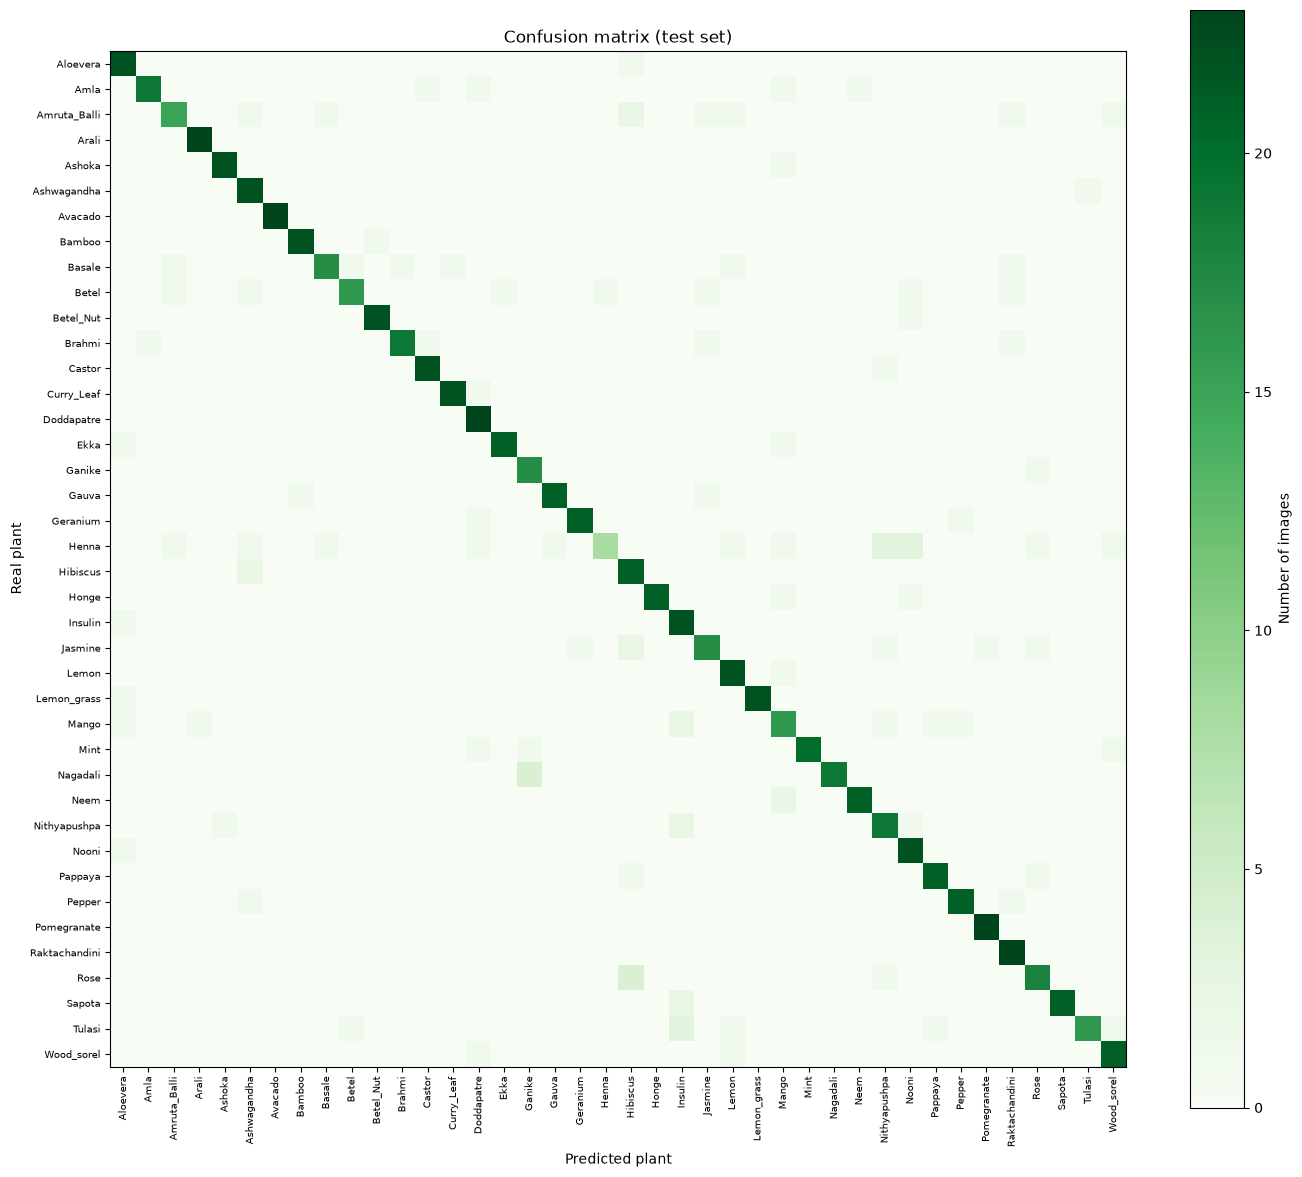

In [14]:
import os, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

BASE_DIR  = r"C:\Users\LENOVO\Desktop\AI project\Medicinal-plant"
MODEL_DIR = os.path.join(BASE_DIR, "models")
SPLIT_DIR = os.path.join(BASE_DIR, "dataset")
IMG_SIZE  = (160, 160)
BATCH     = 16

# 1. Load the saved model and the plant names
model = tf.keras.models.load_model(os.path.join(MODEL_DIR, "herbal_model.keras"))
with open(os.path.join(MODEL_DIR, "classes.json")) as f:
    class_names = json.load(f)

# 2. Load the test images (never used in training)
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(SPLIT_DIR, "test"),
    image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="categorical", shuffle=False,
    class_names=class_names)

# 3. Overall accuracy
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"\nTEST ACCURACY: {test_acc:.2%}   (loss {test_loss:.3f})\n")

# 4. Predictions for every test image
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)

# 5. Per-plant report
print(classification_report(y_true, y_pred, target_names=class_names, digits=2))

with open(os.path.join(BASE_DIR, "test_report.txt"), "w", encoding="utf-8") as f:
    f.write(f"Test accuracy: {test_acc:.4f}\n\n")
    f.write(classification_report(y_true, y_pred, target_names=class_names, digits=2))

# 6. Weakest plants (lowest recall)
rep = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
weak = sorted(((n, rep[n]["recall"], int(rep[n]["support"])) for n in class_names),
              key=lambda x: x[1])[:8]
print("WEAKEST 8 PLANTS (share of its test photos found correctly):")
for n, r, s in weak:
    print(f"  {n:15s} {r:.0%}  ({s} test photos)")

# 7. Most common mix-ups
cm = confusion_matrix(y_true, y_pred)
pairs = [(cm[i, j], class_names[i], class_names[j])
         for i in range(len(class_names)) for j in range(len(class_names))
         if i != j and cm[i, j] > 0]
pairs.sort(reverse=True)
print("\nMOST COMMON MIX-UPS (real plant -> predicted as):")
for count, real, pred in pairs[:10]:
    print(f"  {real:15s} -> {pred:15s} x{count}")

# 8. Confusion matrix picture
plt.figure(figsize=(14, 12))
plt.imshow(cm, cmap="Greens")
plt.colorbar(label="Number of images")
plt.xticks(range(len(class_names)), class_names, rotation=90, fontsize=7)
plt.yticks(range(len(class_names)), class_names, fontsize=7)
plt.xlabel("Predicted plant")
plt.ylabel("Real plant")
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, "confusion_matrix.png"), dpi=150)
plt.show()